# ChoixSocial-11 — Vote par approbation : la relaxation d'Arrow la plus simple

**Série GameTheory / SocialChoice** · C# / .NET 9 (BCL, 0 NuGet pour les algorithmes) · Figure ScottPlot 5

**Navigation** : [<< ChoixSocial-10 (précédent)](ChoixSocial-10-Manipulation-Strategique-MultiWinner-CSharp.ipynb) | [Index](README.md)

Le carnet **01** (Arrow) a établi qu'*aucune* règle de vote ne satisfait à la fois la Pareto,
l'indépendance des alternatives superflues (IIA) et le non-dictatorat. Ce carnet prend le
contre-pied : au lieu de chercher une règle impossible, on étudie une règle **réelle et
largement déployée** — le **vote par approbation** — et on mesure **ce qu'elle abandonne**
(elle enfreint un axiome) contre **ce qu'elle change** (le prix d'un bulletin stratégique :
un point).


In [1]:
using System;
using System.Collections.Generic;
using System.Linq;

// C# / .NET Interactive — BCL seul pour les algorithmes (0 NuGet).
// La figure utilise ScottPlot 5, comme les jumeaux C# de la série.

Console.WriteLine(".NET " + Environment.Version);
Console.WriteLine("ChoixSocial-11 — Vote par approbation");


The below script needs to be able to find the current output cell; this is an easy method to get it.

.NET 10.0.15


ChoixSocial-11 — Vote par approbation


## Que change le vote par approbation ?

Les règles de **classement** (pluralité, Borda, IRV) obligent chaque votant à **hiérarchiser**
les candidats. Le vote par approbation casse cette contrainte :

- chaque votant **approuve un sous-ensemble** de candidats (aucun, un, plusieurs, tous) ;
- le **score** d'un candidat est le nombre de votants qui l'approuvent ;
- le **gagnant** est le candidat au score d'approbation le plus élevé.

On ne demande plus un ordre complet, mais un simple seuil *approuvé / non approuvé*. C'est
précisément cet assouplissement qui permet de **relâcher l'IIA** d'Arrow de façon contrôlée —
au prix d'une **vulnérabilité propre** que ce carnet rend tangible.


In [2]:
using System;
using System.Collections.Generic;
using System.Linq;

// Les trois règles, from scratch en BCL (0 NuGet). Un bulletin d'approbation est un
// ensemble de candidats ; un bulletin de classement est une liste ordonnée.
static class C11
{
    // Score d'approbation : nombre de votants qui approuvent chaque candidat.
    public static Dictionary<string, int> ScoresApprobation(IList<HashSet<string>> bulletins, IEnumerable<string> cands)
    {
        var scores = cands.ToDictionary(c => c, _ => 0);
        foreach (var b in bulletins)
            foreach (var c in b)
                if (scores.ContainsKey(c)) scores[c] += 1;
        return scores;
    }

    // Gagnant par approbation (ex-aequo : premier alphabétiquement, pour rester déterministe).
    public static string GagnantApprobation(IList<HashSet<string>> bulletins, IEnumerable<string> cands)
    {
        return ScoresApprobation(bulletins, cands)
            .OrderByDescending(kv => kv.Value).ThenBy(kv => kv.Key).First().Key;
    }

    // Pluralité : une voix pour le premier de chaque bulletin de classement.
    public static Dictionary<string, int> ScoresPluralite(IList<List<string>> classements, IEnumerable<string> cands)
    {
        var scores = cands.ToDictionary(c => c, _ => 0);
        foreach (var cl in classements)
            if (cl.Count > 0) scores[cl[0]] += 1;
        return scores;
    }

    public static string GagnantPluralite(IList<List<string>> classements, IEnumerable<string> cands)
    {
        return ScoresPluralite(classements, cands)
            .OrderByDescending(kv => kv.Value).ThenBy(kv => kv.Key).First().Key;
    }

    // Borda : n-1, n-2, ... points décroissants.
    public static Dictionary<string, int> ScoresBorda(IList<List<string>> classements, IEnumerable<string> cands)
    {
        int n = cands.Count();
        var scores = cands.ToDictionary(c => c, _ => 0);
        foreach (var cl in classements)
            for (int i = 0; i < cl.Count && i < n; i++)
                scores[cl[i]] += (n - 1 - i);
        return scores;
    }

    public static string GagnantBorda(IList<List<string>> classements, IEnumerable<string> cands)
    {
        return ScoresBorda(classements, cands)
            .OrderByDescending(kv => kv.Value).ThenBy(kv => kv.Key).First().Key;
    }
}

Console.WriteLine("Règles chargées : " + typeof(C11).Name);


Règles chargées : C11


## L'expérience : trois règles, deux réponses

On construit un petit profil où les règles **divergent**. Un électorat divisé entre deux
camps, avec un **candidat de compromis** qui rassemble le plus large consensus :

- la **pluralité** élève le favori du plus grand camp ;
- **Borda** lisse les classements ;
- l'**approbation** élève le candidat que le **plus de monde** accepte.

Le « bon » résultat dépend de l'axiome que l'on veut préserver — c'est la tension d'Arrow,
rendue arithmétique.


In [3]:
// 6 votants, 3 candidats : A (candidat du camp 1), B (compromis), C (candidat du camp 2).
// 4 votants du camp A (A > B > C), 2 du camp C (C > B > A). B est le consensus des deux camps.
string[] cands11 = { "A", "B", "C" };

// Bulletins de classement (pour la pluralité et Borda).
List<List<string>> classements11 = new List<List<string>>
{
    new List<string> { "A", "B", "C" },
    new List<string> { "A", "B", "C" },
    new List<string> { "A", "B", "C" },
    new List<string> { "A", "B", "C" },
    new List<string> { "C", "B", "A" },
    new List<string> { "C", "B", "A" },
};

// Bulletins d'approbation : chacun approuve SON premier choix ET le compromis B.
// -> B récolte 6 approbations, A et C seulement 4 et 2.
List<HashSet<string>> approval11 = new List<HashSet<string>>
{
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "C", "B" },
    new HashSet<string> { "C", "B" },
};

Console.WriteLine($"Pluralité   -> {C11.GagnantPluralite(classements11, cands11)}   ({string.Join(", ", C11.ScoresPluralite(classements11, cands11).Select(kv => kv.Key + "=" + kv.Value))})");
Console.WriteLine($"Borda       -> {C11.GagnantBorda(classements11, cands11)}   ({string.Join(", ", C11.ScoresBorda(classements11, cands11).Select(kv => kv.Key + "=" + kv.Value))})");
Console.WriteLine($"Approbation -> {C11.GagnantApprobation(approval11, cands11)}   ({string.Join(", ", C11.ScoresApprobation(approval11, cands11).Select(kv => kv.Key + "=" + kv.Value))})");


Pluralité   -> A   (A=4, B=0, C=2)


Borda       -> A   (A=8, B=6, C=4)


Approbation -> B   (A=4, B=6, C=2)


## Le résultat central : un bulletin ne pèse que d'un point

C'est ce que le vote par approbation **change** en relâchant l'IIA — et il faut en prendre la
mesure exacte. Un bulletin ne peut nuire à un candidat que d'**un point** : le sien. Pour faire
basculer un résultat, un calculateur doit donc viser un écart d'exactement un point, ou agir
à plusieurs. La règle ne rend pas le calcul impossible ; elle en fixe le **prix**.

**Ce qui est vrai, et rien de plus.** Approuver un candidat que l'on préfère à un candidat
déjà approuvé ne peut pas nuire : ce geste augmente d'un point le score du candidat préféré,
et seulement le sien, donc il ne change le gagnant que si c'est lui qui l'emporte. Un bulletin
qui approuve un candidat *sans* approuver un candidat préféré est donc **dominé** par celui
qui approuve les deux. Mais cela ne dit rien du **choix du seuil** — combien de candidats on
approuve : approuver son premier choix seul, ou approuver aussi son second, sont deux bulletins
sincères, et le bon dépend des scores des autres. Aucune stratégie n'est dominante à elle seule.

On rend le mécanisme visible : un calculateur retire une approbation pour faire basculer le
résultat — et le résultat **ne bouge pas**.


In [4]:
// Duel A vs C, B marginal. 5 votants : 3 du camp A, 2 du camp C, tous approuvant aussi B.
string[] duelCands = { "A", "B", "C" };
List<HashSet<string>> duel11 = new List<HashSet<string>>
{
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "A", "B" },
    new HashSet<string> { "C", "B" },
    new HashSet<string> { "C", "B" },
};

Console.WriteLine($"Sincère   -> {C11.GagnantApprobation(duel11, duelCands)}   ({string.Join(", ", C11.ScoresApprobation(duel11, duelCands).Select(kv => kv.Key + "=" + kv.Value))})");

// Un votant du camp C retire stratégiquement son approbation de B, en calcul :
List<HashSet<string>> duel11s = new List<HashSet<string>>(duel11);
duel11s[3] = new HashSet<string> { "C" };   // plus de B

Console.WriteLine($"Retrait B -> {C11.GagnantApprobation(duel11s, duelCands)}   ({string.Join(", ", C11.ScoresApprobation(duel11s, duelCands).Select(kv => kv.Key + "=" + kv.Value))})");


Sincère   -> B   (A=3, B=5, C=2)


Retrait B -> B   (A=3, B=4, C=2)


## Le coût : approbation peut élire le « second choix »

Le revers de la médaille. Parce que le score d'un candidat dépend de **tout** le profil,
l'approbation **enfreint l'IIA** : la présence d'un candidat tierce peut infléchir qui l'emporte.
Et son échec caractéristique est celui que l'expérience ci-dessus a déjà produit — élire un
**consensus de repli** que personne ne met en tête.

**Le calcul n'est pas aboli, il est déplacé.** Relisons la sortie du duel : le compromis passe
de 5 à 4 approbations et reste en tête, donc le retrait d'**un** votant ne paie pas. Mais ce
sont les votants du camp A qui auraient intérêt à le tenter : si **deux** d'entre eux retiraient
ensemble leur approbation du compromis, celui-ci tomberait au niveau du favori de leur camp — et
le tie-break alphabétique élirait ce favori, qu'ils préfèrent. Les deux bulletins, avec ou sans
le compromis, sont sincères ; seul le **seuil** change. Le même profil accepte donc un calcul
qui paie, à condition d'être assez nombreux. C'est le même ordre de défaut que le théorème de
Gibbard-Satterthwaite (carnet 05) a formalisé : dès que plusieurs issues sont possibles, il
existe des profils où le calcul paie. L'approbation n'y fait pas exception ; elle en rend le
prix lisible — un point par bulletin.

On chiffre l'autre face de ce coût sur le profil de l'expérience.


In [5]:
// Le coût, chiffré : B gagne l'approbation alors qu'aucun votant ne le met en TÊTE, et qu'A
// est le premier choix de la majorité (4 sur 6).
int premiers11 = classements11.Count(cl => cl[0] == "B");
int premiersA11 = classements11.Count(cl => cl[0] == "A");

Console.WriteLine($"Premiers choix : A={premiersA11}/6, B={premiers11}/6");
Console.WriteLine($"Gagnant par approbation : {C11.GagnantApprobation(approval11, cands11)}");
Console.WriteLine(premiers11 == 0
    ? "-> un candidat à 0 premier choix devance le favori de la majorité : le coût de l'approbation."
    : "-> (ce profil ne manifeste pas le coût)");


Premiers choix : A=4/6, B=0/6


Gagnant par approbation : B


-> un candidat à 0 premier choix devance le favori de la majorité : le coût de l'approbation.


## En figure

Les scores d'approbation du profil de l'expérience : la barre du compromis **B** domine,
bien qu'aucun votant ne l'ait classé en tête.


Installed Packages ScottPlot, 5.0.55


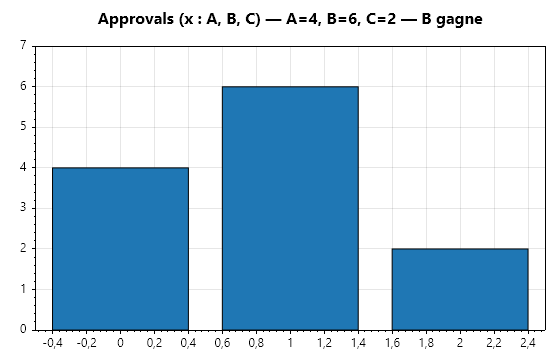


warning CS1701: En supposant que la référence d'assembly 'Microsoft.AspNetCore.Html.Abstractions, Version=2.3.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' utilisée par 'Microsoft.DotNet.Interactive' correspond à l'identité 'Microsoft.AspNetCore.Html.Abstractions, Version=10.0.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' de 'Microsoft.AspNetCore.Html.Abstractions', il se peut que vous deviez fournir une stratégie runtime



In [6]:
#r "nuget: ScottPlot, 5.0.55"

// Figure : scores d'approbation (A, B, C) du profil de l'expérience.
var appScores11 = C11.ScoresApprobation(approval11, cands11);
double[] xs11 = { 0, 1, 2 };
double[] ys11 = { appScores11["A"], appScores11["B"], appScores11["C"] };

var plt11 = new ScottPlot.Plot();
plt11.Add.Bars(xs11, ys11);
plt11.Axes.SetLimits(-0.5, 2.5, 0, 7);
plt11.Title($"Approvals (x : A, B, C) — A={appScores11["A"]}, B={appScores11["B"]}, C={appScores11["C"]} — B gagne");

string fig11 = plt11.GetPngHtml(560, 360);
display(HTML(fig11));

## À retenir

- Le vote par **approbation** est la **relaxation d'Arrow la plus simple** : on abandonne
  l'ordre complet au profit d'un seuil, et l'on **enfreint l'IIA** en retour.
- Un bulletin ne peut nuire à un candidat que d'**un point** : sur le duel, le calculateur
  isolé ne fait rien, mais le calcul paie dès qu'il est collectif, ou que l'écart est d'un
  point. La sincérité n'est **pas** une stratégie dominante — c'est le choix du seuil qui décide.
- Et l'on conserve un **coût propre**, tangible ici : le risque d'élire un **consensus de
  repli** que personne ne met en tête, devant le favori de la majorité.

Changer d'axiome, c'est changer de réponse — exactement ce que le théorème d'Arrow laissait
pressentir, et que ce carnet rend arithmétique.


## Exercices

**1. Ex-aequo d'approbation.** Construisez deux bulletins (3 candidats) qui laissent deux
candidats au même score d'approbation, et observez que le tie-break alphabétique tranche.

**2. Regret du votant.** Pour chaque bulletin du profil `approval11`, calculez la différence
entre le score d'approbation du candidat que le votant met **en tête** (son 1er choix) et le
score du gagnant.

**3. Le consensus sans premier choix.** Généralisez l'expérience : un profil d'au moins 4
votants où le gagnant par approbation est mis en **1re place par zéro** votant.


In [7]:
// Exercice 1 — Ex-aequo d'approbation
// Objectif : 2 bulletins sur 3 candidats, deux candidats à score ÉGAUX.
// Indice : un profil où chacun des deux est approuvé une fois.
List<HashSet<string>> ex11a = new List<HashSet<string>>
{
    // TODO etudiant : remplissez les deux bulletins
};
// string ex11a_g = C11.GagnantApprobation(ex11a, new[] { "A", "B", "C" });
// Console.WriteLine("Gagnant (tie-break alpha) : " + ex11a_g);
Console.WriteLine("Exercice 1 à compléter");


Exercice 1 à compléter


In [8]:
// Exercice 2 — Regret du votant
// Objectif : pour CHAQUE bulletin de approval11, la différence entre le score du 1er choix
//   du votant et le score du gagnant par approbation.
// Indice : C11.ScoresApprobation() donne tous les scores ; le 1er choix est le 1er élément
//   du classement correspondant (classements11).
double[] regrets11 = { 0, 0, 0, 0, 0, 0 };   // TODO etudiant : remplissez
Console.WriteLine("Exercice 2 à compléter — regrets : " + string.Join(", ", regrets11));


Exercice 2 à compléter — regrets : 0, 0, 0, 0, 0, 0


In [9]:
// Exercice 3 — Le consensus sans premier choix
// Objectif : un profil (>= 4 votants) dont le gagnant par approbation est mis en 1re place
//   par ZÉRO votant. L'expérience du carnet en est un ; généralisez-la.
List<HashSet<string>> ex11c = new List<HashSet<string>>();
// bool ex11c_ok = ...;   // TODO etudiant
Console.WriteLine("Exercice 3 à compléter");


Exercice 3 à compléter


## Pour aller plus loin

- **ChoixSocial-01** — le théorème d'Arrow dont ce carnet étudie la relaxation.
- **ChoixSocial-05** — Gibbard-Satterthwaite : le stratégisme, formalisé.
- **ChoixSocial-07** — l'approbation transposée aux **comités** (core, approbation multipartite).
- **En pratique** : le vote par approbation est en usage dans plusieurs scrutins (primaires
  américaines, référendums) précisément pour sa robustesse au calcul.
